# French motor pricing GLM: frequency model

Data: `freMTPL2freq` (policies, exposure, claim counts) and `freMTPL2sev` (individual claim amounts).

This notebook covers:
1. **Data**: load, aggregate severity per policy, join, cap
2. **Cleaning & EDA**: bin rating factors, look at distributions and one-way frequencies
3. **Frequency model**: Poisson GLM with a log-exposure offset, overdispersion check, negative binomial comparison

The severity model comes later and is not built here.

> **R users:** cells marked `# R note:` point out where Python/statsmodels differs from `glm()`.

In [1]:
# Imports and global settings. The fixed seed makes the train/test split reproducible.
# R note: `import x as y` is like library(x), but everything stays namespaced (np.log, pd.cut, ...).
#         statsmodels.formula.api (smf) gives R-style formulas; statsmodels.api (sm) holds families/links.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_poisson_deviance

SEED = 42

# One colour for all single-series charts, light grid so the data stands out
BAR_COLOR = "#2a78d6"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
})
pd.set_option("display.float_format", "{:,.4f}".format)

## Step 1: Data

In [2]:
# Load both tables from OpenML (IDs 41214 = freq, 41215 = sev). If there is no internet
# or OpenML is down, fall back to local CSVs with the same names in this folder.
try:
    freq = fetch_openml(data_id=41214, as_frame=True).frame
    sev = fetch_openml(data_id=41215, as_frame=True).frame
    print("Loaded from OpenML")
except Exception as e:
    print(f"OpenML failed ({e}); reading local CSVs")
    freq = pd.read_csv("freMTPL2freq.csv")
    sev = pd.read_csv("freMTPL2sev.csv")

print("freq:", freq.shape, " sev:", sev.shape)
freq.head()

Loaded from OpenML
freq: (678013, 12)  sev: (26639, 2)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0000,1,0.1000,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0000,1,0.7700,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0000,1,0.7500,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0000,1,0.0900,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0000,1,0.8400,B,7,0,46,50,B12,'Diesel',76,R72


In [3]:
# Fix two OpenML quirks: IDpol comes in as float in freq (int in sev), which would break the join,
# and VehGas values carry literal quotes ("'Diesel'").
freq["IDpol"] = freq["IDpol"].astype("int64")
freq["VehGas"] = freq["VehGas"].astype(str).str.strip("'")
freq.dtypes

IDpol            int64
ClaimNb          int64
Exposure       float64
Area          category
VehPower         int64
VehAge           int64
DrivAge          int64
BonusMalus       int64
VehBrand      category
VehGas             str
Density          int64
Region        category
dtype: object

In [4]:
# sev has one row per claim. Sum to one row per policy, then left join so every policy is kept
# (policies without claims get NaN, which we set to 0).
# R note: groupby().sum() ~ aggregate(ClaimAmount ~ IDpol, sev, sum);
#         merge(how="left") ~ merge(freq, sev_agg, all.x = TRUE).
sev_agg = sev.groupby("IDpol", as_index=False)["ClaimAmount"].sum()

df = freq.merge(sev_agg, on="IDpol", how="left")
df["ClaimAmount"] = df["ClaimAmount"].fillna(0)

print("Rows after join:", len(df), "(freq had", len(freq), ")")
print("Policies with ClaimNb > 0 but no amount in sev:", ((df["ClaimNb"] > 0) & (df["ClaimAmount"] == 0)).sum())
print("Policies with an amount but ClaimNb == 0:     ", ((df["ClaimNb"] == 0) & (df["ClaimAmount"] > 0)).sum())

Rows after join: 678013 (freq had 678013 )
Policies with ClaimNb > 0 but no amount in sev: 9116
Policies with an amount but ClaimNb == 0:      0


The first mismatch count is a known feature of this dataset: some policies report claims but have no amounts in `freMTPL2sev`.
It does not affect the frequency model, but the severity step will need to handle it.

In [5]:
# Cap ClaimNb at 4 (the few policies with 5-16 claims are likely data errors and would dominate
# the likelihood) and Exposure at 1 year (a handful of policies exceed one year).
print("ClaimNb before capping:", df["ClaimNb"].value_counts().sort_index().to_dict())
print("Exposure > 1:", (df["Exposure"] > 1).sum(), "policies")

df["ClaimNb"] = df["ClaimNb"].clip(upper=4)
df["Exposure"] = df["Exposure"].clip(upper=1)

print("ClaimNb after capping: ", df["ClaimNb"].value_counts().sort_index().to_dict())

ClaimNb before capping: {0: 643953, 1: 32178, 2: 1784, 3: 82, 4: 7, 5: 2, 6: 1, 8: 1, 9: 1, 11: 3, 16: 1}
Exposure > 1: 1224 policies
ClaimNb after capping:  {0: 643953, 1: 32178, 2: 1784, 3: 82, 4: 16}


## Step 2: Cleaning and EDA

In [6]:
# Bin the three main continuous rating factors. The relationship with frequency is not linear
# (e.g. young drivers), so bands let the GLM fit a separate level for each group.
# BonusMalus is capped at 150 first because very few policies are above it.
# R note: pd.cut(x, bins, labels) ~ cut(x, breaks, labels). Intervals are right-closed by
#         default in both, so (17, 20] means ages 18-20.
df["BonusMalus"] = df["BonusMalus"].clip(upper=150)

df["DrivAge_bin"] = pd.cut(
    df["DrivAge"],
    bins=[17, 20, 25, 30, 40, 50, 60, 70, np.inf],
    labels=["18-20", "21-25", "26-30", "31-40", "41-50", "51-60", "61-70", "71+"],
)
df["VehAge_bin"] = pd.cut(
    df["VehAge"],
    bins=[-1, 0, 2, 5, 10, 15, np.inf],
    labels=["0", "1-2", "3-5", "6-10", "11-15", "16+"],
)
df["BonusMalus_bin"] = pd.cut(
    df["BonusMalus"],
    bins=[0, 50, 60, 70, 80, 90, 100, 125, 150],
    labels=["50", "51-60", "61-70", "71-80", "81-90", "91-100", "101-125", "126-150"],
)

# No policy should fall outside the bins
df[["DrivAge_bin", "VehAge_bin", "BonusMalus_bin"]].isna().sum()

DrivAge_bin       0
VehAge_bin        0
BonusMalus_bin    0
dtype: int64

In [7]:
# Split 80/20 now, before EDA and modelling, so the test set is never used to make modelling choices.
# The binning above is a fixed rule (no values learned from the data), so doing it before the split is safe.
# R note: this replaces set.seed(42); idx <- sample(nrow(df), 0.8 * nrow(df)).
train, test = train_test_split(df, test_size=0.2, random_state=SEED)

print(f"train: {len(train):,} policies, {train['Exposure'].sum():,.0f} exposure years, {train['ClaimNb'].sum():,} claims")
print(f"test:  {len(test):,} policies, {test['Exposure'].sum():,.0f} exposure years, {test['ClaimNb'].sum():,} claims")

train: 542,410 policies, 286,764 exposure years, 28,817 claims
test:  135,603 policies, 71,596 exposure years, 7,239 claims


ClaimNb
0   0.9498
1   0.0474
2   0.0026
3   0.0001
4   0.0000
Name: share, dtype: float64


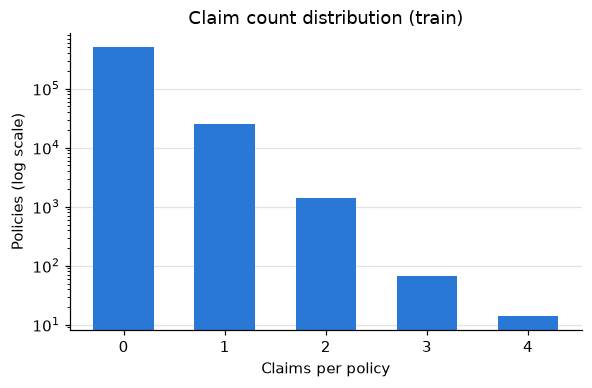

In [8]:
# Claim count distribution. Almost all policies have zero claims, so the y-axis is on a log scale;
# otherwise the bars for 2+ claims would not be visible.
counts = train["ClaimNb"].value_counts().sort_index()
print((counts / counts.sum()).rename("share"))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(counts.index.astype(str), counts.values, color=BAR_COLOR, width=0.6)
ax.set_yscale("log")
ax.set_xlabel("Claims per policy")
ax.set_ylabel("Policies (log scale)")
ax.set_title("Claim count distribution (train)")
plt.show()

count      21,044.0000
mean        2,282.8888
std        32,142.2937
min             1.0000
50%         1,172.0000
90%         2,767.3220
99%        16,252.0225
99.9%     151,542.8242
max     4,075,400.5600
Name: ClaimAmount, dtype: float64

Largest 1% of claims = 38.6% of total claim cost


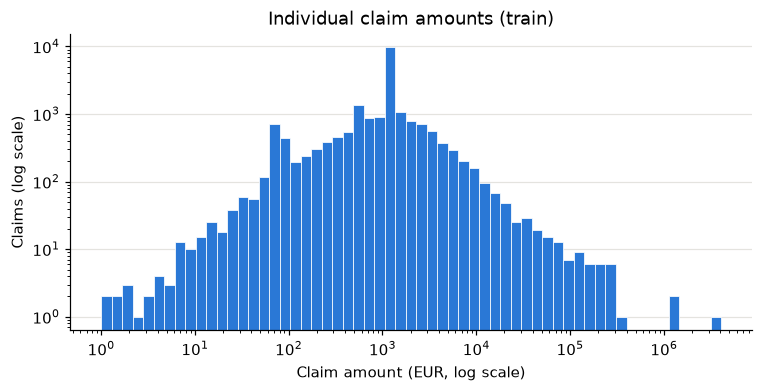

In [9]:
# Severity tail. Use the individual claims from sev (one row per claim, not the per-policy sums)
# for policies in the training set. Bins are spaced evenly on a log scale because amounts
# range from a few euros to millions.
train_claims = sev.loc[sev["IDpol"].isin(train["IDpol"]), "ClaimAmount"]
print(train_claims.describe(percentiles=[0.5, 0.9, 0.99, 0.999]))
top_1pct = train_claims >= train_claims.quantile(0.99)
print(f"\nLargest 1% of claims = {train_claims[top_1pct].sum() / train_claims.sum():.1%} of total claim cost")

bins = np.logspace(np.log10(train_claims.min()), np.log10(train_claims.max()), 60)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train_claims, bins=bins, color=BAR_COLOR, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Claim amount (EUR, log scale)")
ax.set_ylabel("Claims (log scale)")
ax.set_title("Individual claim amounts (train)")
plt.show()

The spike around EUR 1,100-1,200 is a known feature of this dataset (fixed-rate claim settlements). The long right tail matters
for the severity model later, not for frequency.

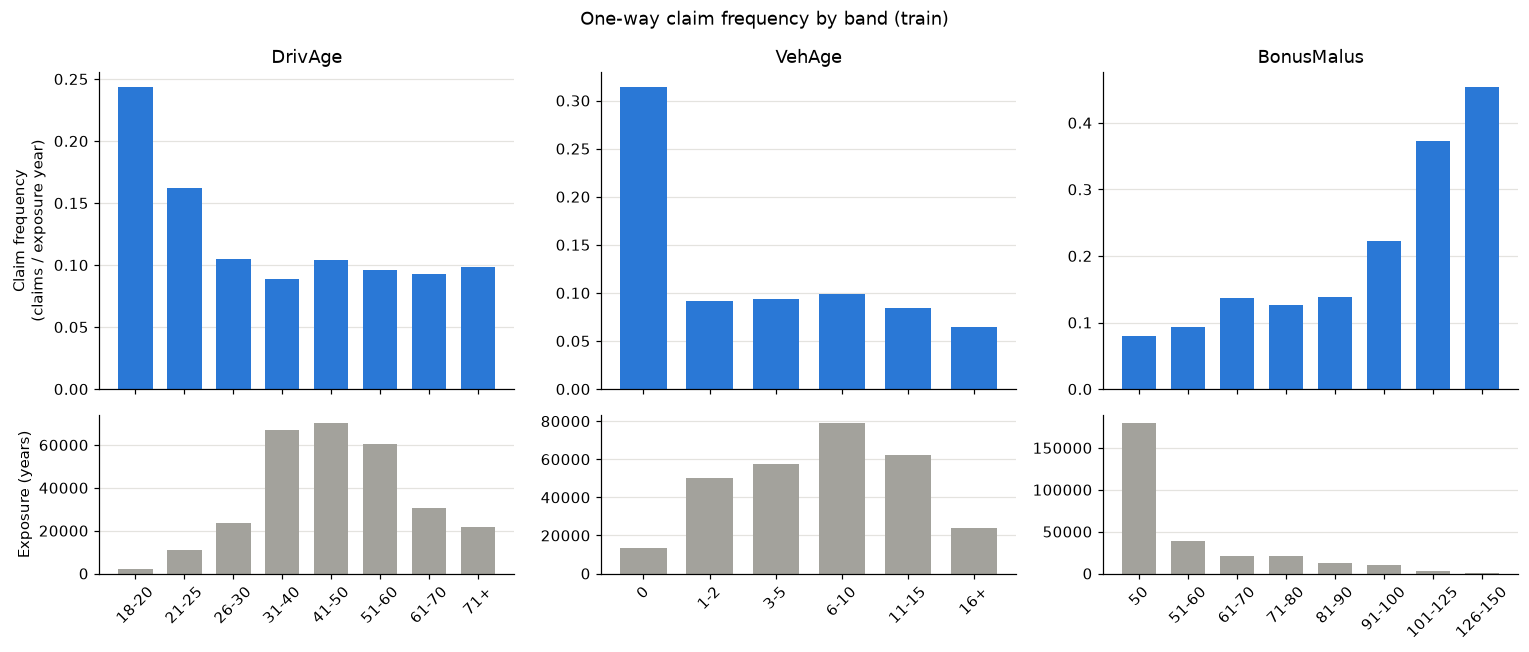

,exposure,claims,frequency
DrivAge_bin,,,
18-20,"2,054.0232",500,0.2434
21-25,"10,968.1616",1776,0.1619
26-30,"23,396.2995",2459,0.1051
31-40,"67,185.3493",5975,0.0889
41-50,"70,452.2434",7352,0.1044
51-60,"60,490.5302",5791,0.0957
61-70,"30,667.6462",2850,0.0929
71+,"21,549.6589",2114,0.0981


,exposure,claims,frequency
VehAge_bin,,,
0,"13,422.2426",4214,0.3140
1-2,"49,904.1464",4546,0.0911
3-5,"57,753.3762",5382,0.0932
6-10,"79,249.8283",7851,0.0991
11-15,"62,270.9331",5275,0.0847
16+,"24,163.3857",1549,0.0641


,exposure,claims,frequency
BonusMalus_bin,,,
50,"180,166.3684",14451,0.0802
51-60,"38,349.3121",3600,0.0939
61-70,"21,261.7196",2922,0.1374
71-80,"21,255.8226",2690,0.1266
81-90,"12,146.7137",1679,0.1382
91-100,"10,684.5117",2371,0.2219
101-125,"2,599.6096",968,0.3724
126-150,299.8547,136,0.4536


In [10]:
# One-way claim frequency by band: total claims / total exposure (not the mean of ClaimNb, which
# would ignore that many policies are in force for only part of the year).
# Exposure per band is shown underneath to indicate how much data sits behind each frequency.
# R note: groupby().agg() ~ dplyr::group_by() |> summarise(); observed=True drops empty categories.
def one_way(data, var):
    out = data.groupby(var, observed=True).agg(exposure=("Exposure", "sum"), claims=("ClaimNb", "sum"))
    out["frequency"] = out["claims"] / out["exposure"]
    return out

bin_vars = ["DrivAge_bin", "VehAge_bin", "BonusMalus_bin"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex="col", gridspec_kw={"height_ratios": [2, 1]})
for j, var in enumerate(bin_vars):
    ow = one_way(train, var)
    labels = ow.index.astype(str)
    axes[0, j].bar(labels, ow["frequency"], color=BAR_COLOR, width=0.7)
    axes[0, j].set_title(var.replace("_bin", ""))
    axes[1, j].bar(labels, ow["exposure"], color="#a3a29c", width=0.7)
    axes[1, j].tick_params(axis="x", rotation=45)
axes[0, 0].set_ylabel("Claim frequency\n(claims / exposure year)")
axes[1, 0].set_ylabel("Exposure (years)")
fig.suptitle("One-way claim frequency by band (train)")
fig.tight_layout()
plt.show()

for var in bin_vars:
    display(one_way(train, var))

Things to note:
- **DrivAge**: frequency is highest for 18-20, falls to its lowest around 31-40, and is roughly flat after that.
- **VehAge**: new vehicles (age 0) have a much higher frequency. Short exposures are concentrated in this band, so this pattern needs checking; it is a known artefact of this dataset.
- **BonusMalus**: frequency rises steadily with the level, as expected. The top bands have little exposure.

## Step 3: Frequency model

In [11]:
# Poisson GLM for ClaimNb with a log link and log(Exposure) as offset. The model then describes
# claims per year of exposure: log E[N] = log(Exposure) + X*beta.
#
# Predictors:
#   - the three bands from Step 2
#   - Area, VehGas, VehBrand, Region, VehPower as categoricals
#   - log(Density) as a continuous term (density spans several orders of magnitude)
# The base level of each banded factor is its highest-exposure band, so each relativity is
# measured against a well-populated reference.
#
# R notes:
#   - C(x) ~ factor(x). C(x, Treatment("41-50")) ~ relevel(factor(x), ref = "41-50").
#   - The offset is passed as an ARGUMENT (offset=np.log(...)), not written inside the formula.
#     R accepts offset(log(Exposure)) in the formula too; statsmodels formulas have no offset() term.
#   - The family is an object: sm.families.Poisson() uses the log link by default
#     (explicitly: sm.families.Poisson(link=sm.families.links.Log())).
#   - smf.glm(...) only defines the model; .fit() estimates it. R's glm() does both at once.
formula = (
    "ClaimNb ~ C(DrivAge_bin, Treatment('41-50'))"
    " + C(VehAge_bin, Treatment('6-10'))"
    " + C(BonusMalus_bin, Treatment('50'))"
    " + C(Area) + C(VehGas) + C(VehBrand, Treatment('B1'))"
    " + C(Region, Treatment('R24')) + C(VehPower, Treatment(6))"
    " + np.log(Density)"
)

poisson = smf.glm(
    formula,
    data=train,
    family=sm.families.Poisson(),
    offset=np.log(train["Exposure"]),
).fit()

print(poisson.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:                            GLM   Df Residuals:                   542341
Model Family:                 Poisson   Df Model:                           68
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1233e+05
Date:                Wed, 30 Sep 2026   Deviance:                   1.6927e+05
Time:                        22:09:39   Pearson chi2:                 1.22e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01781
Covariance Type:            nonrobust                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------

In [12]:
# Exponentiated coefficients = multiplicative relativities on claim frequency (e.g. 1.5 = 50% more
# claims per year than the base level, all else equal). The intercept becomes the base frequency.
# R note: exp(coef(m)) and exp(confint.default(m)) -> np.exp(m.params) and np.exp(m.conf_int()).
#         conf_int() gives Wald intervals, not the profile-likelihood intervals of MASS's confint().
def relativities(res):
    ci = np.exp(res.conf_int())
    return pd.DataFrame({
        "relativity": np.exp(res.params),
        "ci_low": ci[0],
        "ci_high": ci[1],
        "p_value": res.pvalues,
    })

rel_poisson = relativities(poisson)
with pd.option_context("display.max_rows", 100):
    display(rel_poisson)

,relativity,ci_low,ci_high,p_value
Intercept,0.0716,0.0647,0.0792,0.0000
"C(DrivAge_bin, Treatment('41-50'))[T.18-20]",1.0528,0.9553,1.1602,0.2993
"C(DrivAge_bin, Treatment('41-50'))[T.21-25]",0.7506,0.7082,0.7956,0.0000
"C(DrivAge_bin, Treatment('41-50'))[T.26-30]",0.6185,0.5888,0.6497,0.0000
"C(DrivAge_bin, Treatment('41-50'))[T.31-40]",0.7096,0.6850,0.7351,0.0000
"C(DrivAge_bin, Treatment('41-50'))[T.51-60]",0.9473,0.9152,0.9806,0.0021
"C(DrivAge_bin, Treatment('41-50'))[T.61-70]",0.9271,0.8876,0.9683,0.0007
"C(DrivAge_bin, Treatment('41-50'))[T.71+]",1.0264,0.9771,1.0782,0.2991
"C(VehAge_bin, Treatment('6-10'))[T.0]",3.1055,2.9789,3.2375,0.0000
"C(VehAge_bin, Treatment('6-10'))[T.1-2]",0.9176,0.8822,0.9544,0.0000


In [13]:
# Overdispersion check: Pearson chi2 / residual df. Under a correct Poisson model it is about 1.
# A value well above 1 means the variance exceeds the mean, so Poisson standard errors are too small
# (and p-values too optimistic).
# R note: same as sum(residuals(m, type = "pearson")^2) / df.residual(m).
dispersion = poisson.pearson_chi2 / poisson.df_resid
print(f"Pearson chi2 / df = {poisson.pearson_chi2:,.0f} / {poisson.df_resid:,.0f} = {dispersion:.3f}")
print(f"Deviance / df     = {poisson.deviance / poisson.df_resid:.3f}  (not reliable for low-count data, shown for reference)")

overdispersed = dispersion > 1.1  # rule-of-thumb threshold
print("Overdispersed:", overdispersed)

Pearson chi2 / df = 1,217,016 / 542,341 = 2.244
Deviance / df     = 0.312  (not reliable for low-count data, shown for reference)
Overdispersed: True


In [14]:
# If overdispersed, fit a negative binomial (NB2: Var = mu + alpha * mu^2) with the same formula
# and offset. alpha is estimated jointly with the betas. Starting from the Poisson estimates
# (alpha = 1) with Newton's method converges in a few iterations.
# R notes:
#   - smf.negativebinomial is the equivalent of MASS::glm.nb(). R reports theta; here alpha = 1 / theta.
#   - sm.families.NegativeBinomial() also exists for smf.glm, but it holds alpha FIXED
#     (like the negative.binomial(theta) family in R), which is why the discrete model is used here.
#   - A quasi-Poisson alternative would be poisson_model.fit(scale="X2"), like family = quasipoisson.
if overdispersed:
    negbin = smf.negativebinomial(
        formula,
        data=train,
        offset=np.log(train["Exposure"]),
    ).fit(start_params=np.append(poisson.params.values, 1.0), method="newton", maxiter=100)

    print(negbin.summary())
    print(f"\nalpha = {negbin.params['alpha']:.3f}  (theta = 1/alpha = {1 / negbin.params['alpha']:.3f})")

Optimization terminated successfully.
         Current function value: 0.206662
         Iterations 5


                     NegativeBinomial Regression Results                      
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:               NegativeBinomial   Df Residuals:                   542341
Method:                           MLE   Df Model:                           68
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                 0.03985
Time:                        22:10:55   Log-Likelihood:            -1.1210e+05
converged:                       True   LL-Null:                   -1.1675e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                    coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------
Intercept                                        -2.6308      0.053    -49.179      0.000      -2.736      -2.526
C(DrivAge_bin, Treatment('

In [15]:
# Negative binomial relativities, next to the Poisson ones for comparison. The point estimates
# are usually close; the NB confidence intervals are wider because they account for the extra variance.
if overdispersed:
    rel_negbin = relativities(negbin).drop(index="alpha")
    compare = pd.DataFrame({
        "poisson_rel": rel_poisson["relativity"],
        "negbin_rel": rel_negbin["relativity"],
        "poisson_ci_width": rel_poisson["ci_high"] - rel_poisson["ci_low"],
        "negbin_ci_width": rel_negbin["ci_high"] - rel_negbin["ci_low"],
    })
    with pd.option_context("display.max_rows", 100):
        display(compare)

,poisson_rel,negbin_rel,poisson_ci_width,negbin_ci_width
Intercept,0.0716,0.0720,0.0145,0.0151
"C(DrivAge_bin, Treatment('41-50'))[T.18-20]",1.0528,1.0510,0.2048,0.2177
"C(DrivAge_bin, Treatment('41-50'))[T.21-25]",0.7506,0.7476,0.0873,0.0916
"C(DrivAge_bin, Treatment('41-50'))[T.26-30]",0.6185,0.6142,0.0609,0.0629
"C(DrivAge_bin, Treatment('41-50'))[T.31-40]",0.7096,0.7056,0.0501,0.0517
"C(DrivAge_bin, Treatment('41-50'))[T.51-60]",0.9473,0.9457,0.0655,0.0678
"C(DrivAge_bin, Treatment('41-50'))[T.61-70]",0.9271,0.9229,0.0808,0.0833
"C(DrivAge_bin, Treatment('41-50'))[T.71+]",1.0264,1.0218,0.1011,0.1046
"C(VehAge_bin, Treatment('6-10'))[T.0]",3.1055,3.2640,0.2586,0.2899
"C(VehAge_bin, Treatment('6-10'))[T.1-2]",0.9176,0.9166,0.0721,0.0743


In [16]:
# Compare the two models. AIC uses the training data. On the test set, compare mean Poisson deviance
# (lower = better) and total predicted vs actual claims. Test predictions need the test offset.
# R note: predict(m, newdata = test, type = "response") -> res.predict(test, offset=np.log(test["Exposure"])).
#         statsmodels does not take the offset from newdata automatically, so it has to be passed here.
models = {"Poisson": poisson}
if overdispersed:
    models["Negative binomial"] = negbin

rows = []
for name, res in models.items():
    pred = res.predict(test, offset=np.log(test["Exposure"]))
    rows.append({
        "model": name,
        "n_params": len(res.params),
        "log_lik": res.llf,
        "AIC": res.aic,
        "test_mean_poisson_dev": mean_poisson_deviance(test["ClaimNb"], pred),
        "test_pred_claims": pred.sum(),
        "test_actual_claims": test["ClaimNb"].sum(),
    })
pd.DataFrame(rows).set_index("model")

,n_params,log_lik,AIC,test_mean_poisson_dev,test_pred_claims,test_actual_claims
model,,,,,,
Poisson,69,"-112,326.6876","224,791.3752",0.3148,"7,169.8562",7239
Negative binomial,70,"-112,095.4068","224,330.8136",0.3149,"7,262.0873",7239


### Reading the results

- **Dispersion.** Pearson chi2/df is about 2.2, so the Poisson standard errors understate the uncertainty. The NB estimates alpha of about 0.8 and has an AIC about 460 lower.
- **Point estimates.** The Poisson and NB relativities are very close, and test-set mean Poisson deviance is nearly identical. Overdispersion changes the **uncertainty** (standard errors, CIs, significance) much more than the tariff itself.
- **One-way vs GLM.** In the one-way view, 18-20 year olds have about 2.4x the base frequency. In the GLM their relativity is about 1.05 and not significant. New drivers start on a high BonusMalus, so the BonusMalus bands already capture most of the young-driver effect. Keep this in mind before reading one-way charts as the tariff.
- **Next steps.** Use the NB (or quasi-Poisson) standard errors when deciding which factors or bands to keep or merge. Then move on to the severity model (Step 4, not built here).